# Data Understanding — EDA of Apache Spark Jira tickets and docs

CRISP-DM **Data Understanding**. This notebook only *describes* the raw data and collects evidence for
Data Preparation decisions. It does **not** modify `data/raw/` and does **not** build eval sets.

Inputs (read-only):
- `data/raw/spark_issues.jsonl` — all SPARK issues created ≥ 2020-01-01
- `data/raw/spark_wish_all.jsonl` — all SPARK Wish issues (all time)
- `data/raw/wish_other.jsonl` — latest 1500 Wish issues from all ASF projects
- `data/raw/docs/` — Spark docs (`docs/**/*.md` of the latest stable release)

Findings and the *Decisions needed* list are in `reports/02_data_understanding.md`.
All example texts shown here have e-mails and Jira user mentions masked.

In [1]:
import json
import math
import random
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42

# Chart style: validated default palette, light surface; one fixed hue per class.
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
CLASS_COLORS = {"bug": "#2a78d6", "feature": "#eb6834", "task": "#1baf7a", "idea": "#eda100", "sub-task": "#e87ba4"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 10,
    "legend.frameon": False,
})

In [2]:
# ---------- helpers: tables, text, PII masking ----------

def show(df: pd.DataFrame, index: bool = True) -> None:
    """Render a DataFrame as a Markdown table (copy-pasteable into the report)."""
    df = df.reset_index() if index else df

    def fmt(v):
        if isinstance(v, float):
            return str(int(v)) if v.is_integer() else f"{v:.1f}"
        return str(v).replace("|", "\\|").replace("\n", " ")

    header = "| " + " | ".join(map(str, df.columns)) + " |"
    align = "|" + "|".join("---:" if pd.api.types.is_numeric_dtype(df[c]) else "---" for c in df.columns) + "|"
    rows = ["| " + " | ".join(fmt(v) for v in row) + " |" for row in df.itertuples(index=False)]
    display(Markdown("\n".join([header, align, *rows])))


# e-mail not preceded by '/' (skips URI credentials like spark://driver@host, abfss://container@account)
EMAIL_RE = re.compile(r"(?<![\w.%+\-/])[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}")
# Person names are not detectable in general; these catch the most common explicit forms:
# signatures ("Signed-off-by: Jane Doe", "Regards, Jane Doe") and "Jane Doe <jane@x.org>".
SIGNATURE_NAME_RE = re.compile(
    r"((?:Signed-off-by|Co-authored-by|Reported-by|Author)\s*:\s*|(?:Best |Kind )?[Rr]egards\s*,?\s*|Cheers\s*,?\s*|Thanks\s*,\s*)"
    r"([A-Z][a-z]+(?:[ -][A-Z][a-z]+){1,2})\b")
NAME_BEFORE_EMAIL_RE = re.compile(r"\b([A-Z][a-z]+(?: [A-Z][a-z]+){1,2})(?=\s*(?:\([^)]*\)\s*)?[<\[][^>\]\s]*@)")


QUOTED_NAME_RE = re.compile(r'(?<=")[A-Z][a-z]+(?: [A-Z][a-z]+){1,2}(?=\s*[(<])')  # gpg: "Jane Doe (comment) <…"


def mask_names(text: str) -> str:
    text = QUOTED_NAME_RE.sub("<NAME>", NAME_BEFORE_EMAIL_RE.sub("<NAME>", text))
    return SIGNATURE_NAME_RE.sub(lambda m: m.group(1) + "<NAME>", text)
JIRA_MENTION_RE = re.compile(r"\[~[^\]\s]+\]")
URL_RE = re.compile(r"https?://[^\s\[\]|{}<>\"']+")
# GitHub-style @user: lowercase start, not a known Java/Scala/Python annotation or doc tag, not followed by ( . =
ANNOTATIONS = ("since|param|return|returns|throws|throw|deprecated|deprecate|transient|volatile|inline|tailrec|varargs|note|"
               "see|link|code|group|example|author|version|todo|inheritdoc|value|literal|interface|test|before|after|ignore|"
               "nullable|nonnull|override|scala|unchecked|specialized|native|tparam|constructor|define|usecase|udf|udtf|"
               "pandas_udf|property|classproperty|staticmethod|classmethod|dataclass|abstractmethod|overload|"
               "cached_property|contextmanager|wraps|lru_cache|nowarn|pytest|fixture|patch")
AT_MENTION_RE = re.compile(rf"(?<![\w.@/*{{`$])@(?!(?:{ANNOTATIONS})\b)[a-z][A-Za-z0-9-]{{1,38}}\b(?!\s*[(.=])")
CODE_BLOCK_RE = re.compile(r"\{(code|noformat)[^}]*\}.*?\{\1\}|```.*?```", re.S)
INLINE_CODE_RE = re.compile(r"\{\{.*?\}\}|`[^`\n]*`")


def prose(text: str) -> str:
    """Text without {code}/{noformat}/``` blocks."""
    return CODE_BLOCK_RE.sub(" ", text)


def prose_strict(text: str) -> str:
    """Prose without code blocks and without inline code ({{...}}, `...`)."""
    return INLINE_CODE_RE.sub(" ", prose(text))


def mask_pii(text: str) -> str:
    """Masking used for every example shown in this notebook."""
    return JIRA_MENTION_RE.sub("[~<USER>]", EMAIL_RE.sub("<EMAIL>", mask_names(text)))


def one_line(text: str, n: int = 220) -> str:
    text = re.sub(r"\s+", " ", mask_pii(text)).strip()
    return text if len(text) <= n else text[: n - 1] + "…"


def around(text: str, start: int, end: int, width: int = 90) -> str:
    left = "…" if start > width else ""
    right = "…" if end + width < len(text) else ""
    return left + one_line(text[max(0, start - width): end + width], 10_000) + right


STOP = set("""
a an the and or but if then else of to in on at by for with from into onto over under about as is are was were be been
being am do does did doing have has had having it its this that these those there here which who whom whose what when
where why how not no nor so than too very can could should would will shall may might must i me my we our you your he
him his she her they them their us also just only all any both each few more most other some such own same out up
down off again further once via per etc e.g eg i.e ie let lets see like get gets got one two new now need needs
currently current following way make makes made since because while within without still even well whether
code noformat quote color panel nbsp
""".split())
TOKEN_RE = re.compile(r"[a-z][a-z0-9_]{2,}")


def terms(text: str) -> set[str]:
    return {t for t in TOKEN_RE.findall(URL_RE.sub(" ", text).lower()) if t not in STOP}


def doc_freq(texts) -> Counter:
    c = Counter()
    for t in texts:
        c.update(terms(t))
    return c


def pct(x: float) -> float:
    return round(100 * x, 1)

In [3]:
# ---------- load ----------

def flatten(r: dict) -> dict:
    f = r["fields"]
    project = f.get("project") or {}
    return {
        "key": r["key"],
        "project": project.get("key") or r["key"].split("-")[0],
        "project_name": project.get("name", "Apache Spark"),
        "issuetype": f["issuetype"]["name"],
        "created": f["created"],
        "summary": f.get("summary") or "",
        "description": f.get("description") or "",
        "components": [c["name"] for c in f.get("components") or []],
        "resolution": (f.get("resolution") or {}).get("name", "Unresolved"),
        "status": (f.get("status") or {}).get("name"),
        "labels": f.get("labels") or [],
        "issuelinks": f.get("issuelinks") or [],
    }


def load(name: str) -> pd.DataFrame:
    with (RAW / name).open(encoding="utf-8") as fh:
        df = pd.DataFrame([flatten(json.loads(line)) for line in fh if line.strip()])
    df["created"] = pd.to_datetime(df["created"], utc=True)
    df["year"] = df["created"].dt.year
    df["empty_desc"] = df["description"].str.strip() == ""
    df["summary_words"] = df["summary"].str.split().str.len()
    df["summary_chars"] = df["summary"].str.len()
    df["desc_words"] = df["description"].str.split().str.len()
    df["desc_chars"] = df["description"].str.len()
    return df


spark = load("spark_issues.jsonl")
wish_spark = load("spark_wish_all.jsonl")
wish_other = load("wish_other.jsonl")

overview = pd.DataFrame({
    "file": ["spark_issues.jsonl", "spark_wish_all.jsonl", "wish_other.jsonl"],
    "issues": [len(spark), len(wish_spark), len(wish_other)],
    "unique keys": [spark.key.nunique(), wish_spark.key.nunique(), wish_other.key.nunique()],
    "projects": [spark.project.nunique(), wish_spark.project.nunique(), wish_other.project.nunique()],
    "created from": [d.created.min().date() for d in (spark, wish_spark, wish_other)],
    "created to": [d.created.max().date() for d in (spark, wish_spark, wish_other)],
})
show(overview, index=False)

spark_wish_2020 = set(spark.loc[spark.issuetype == "Wish", "key"])
print("SPARK Wish ≥2020 contained in spark_wish_all:", spark_wish_2020 <= set(wish_spark.key), f"({len(spark_wish_2020)} issues)")
print("wish_other issues that are SPARK issues:", (wish_other.project == "SPARK").sum())
print("wish_other ∩ spark_wish_all:", len(set(wish_other.key) & set(wish_spark.key)))

| file | issues | unique keys | projects | created from | created to |
|---|---:|---:|---:|---|---|
| spark_issues.jsonl | 31290 | 31290 | 1 | 2020-01-01 | 2026-11-15 |
| spark_wish_all.jsonl | 158 | 158 | 1 | 2014-04-17 | 2026-02-18 |
| wish_other.jsonl | 1500 | 1500 | 190 | 2020-09-18 | 2026-11-10 |

SPARK Wish ≥2020 contained in spark_wish_all: True (45 issues)
wish_other issues that are SPARK issues: 41
wish_other ∩ spark_wish_all: 41


## 1. Volume per issuetype and per proposed target class

Proposed mapping of Jira issue types to the four target classes. **core** = unambiguous;
**open** = plausible but needs a decision (see report); **exclude** = not a ticket the assistant should help write.

In [4]:
MAPPING = pd.DataFrame([
    ("Bug", "bug", "core", "Defect report"),
    ("New Feature", "feature", "core", "New functionality"),
    ("Improvement", "feature", "core", "Enhancement of existing functionality = feature request from a user's view"),
    ("Task", "task", "core", "Work item without new user-facing behaviour"),
    ("Wish", "idea", "core", "Jira: 'General wishlist item'"),
    ("Sub-task", "task", "open", "Child of any parent type; parent not downloaded"),
    ("Test", "task", "open", "Engineering work: tests"),
    ("Documentation", "task", "open", "Engineering work: docs"),
    ("Dependency upgrade", "task", "open", "Engineering work: build/deps"),
    ("Story", "feature", "open", "Agile story ≈ feature"),
    ("Brainstorming", "idea", "open", "Exploratory proposal ≈ idea"),
    ("Umbrella", "—", "exclude", "Container of sub-tasks (roadmap text)"),
    ("Epic", "—", "exclude", "Container"),
    ("Question", "—", "exclude", "User-support question, not a work item"),
], columns=["issuetype", "proposed_class", "status", "rationale"])

counts = spark.issuetype.value_counts().rename("issues").rename_axis("issuetype").reset_index()
mapping_table = counts.merge(MAPPING, on="issuetype", how="left")
rare = mapping_table.proposed_class.isna()
mapping_table.loc[rare, ["proposed_class", "status", "rationale"]] = ["—", "exclude", "Admin/infra type, < 10 issues"]
mapping_table["% of SPARK"] = (100 * mapping_table.issues / len(spark)).round(1)
show(mapping_table[["issuetype", "issues", "% of SPARK", "proposed_class", "status", "rationale"]], index=False)

class_of = dict(zip(mapping_table.issuetype, mapping_table.proposed_class))
status_of = dict(zip(mapping_table.issuetype, mapping_table.status))
spark["class"] = spark.issuetype.map(class_of)
spark["map_status"] = spark.issuetype.map(status_of)
spark["class_core"] = spark["class"].where(spark.map_status == "core")

| issuetype | issues | % of SPARK | proposed_class | status | rationale |
|---|---:|---:|---|---|---|
| Sub-task | 12280 | 39.2 | task | open | Child of any parent type; parent not downloaded |
| Improvement | 8142 | 26 | feature | core | Enhancement of existing functionality = feature request from a user's view |
| Bug | 6994 | 22.4 | bug | core | Defect report |
| New Feature | 1002 | 3.2 | feature | core | New functionality |
| Task | 996 | 3.2 | task | core | Work item without new user-facing behaviour |
| Test | 798 | 2.6 | task | open | Engineering work: tests |
| Umbrella | 336 | 1.1 | — | exclude | Container of sub-tasks (roadmap text) |
| Documentation | 309 | 1 | task | open | Engineering work: docs |
| Question | 161 | 0.5 | — | exclude | User-support question, not a work item |
| Dependency upgrade | 114 | 0.4 | task | open | Engineering work: build/deps |
| Epic | 53 | 0.2 | — | exclude | Container |
| Wish | 45 | 0.1 | idea | core | Jira: 'General wishlist item' |
| Story | 36 | 0.1 | feature | open | Agile story ≈ feature |
| Brainstorming | 7 | 0 | idea | open | Exploratory proposal ≈ idea |
| IT Help | 5 | 0 | — | exclude | Admin/infra type, < 10 issues |
| Request | 4 | 0 | — | exclude | Admin/infra type, < 10 issues |
| Github Integration | 3 | 0 | — | exclude | Admin/infra type, < 10 issues |
| RTC | 3 | 0 | — | exclude | Admin/infra type, < 10 issues |
| Planned Work | 1 | 0 | — | exclude | Admin/infra type, < 10 issues |
| Blog - New Blog Request | 1 | 0 | — | exclude | Admin/infra type, < 10 issues |

In [5]:
CLASSES = ["bug", "feature", "task", "idea"]
rows = []
for cls in CLASSES:
    m = mapping_table[mapping_table.proposed_class == cls]
    core, open_ = m[m.status == "core"], m[m.status == "open"]
    rows.append({
        "class": cls,
        "core types": ", ".join(core.issuetype),
        "core issues": int(core.issues.sum()),
        "open candidates": ", ".join(f"{t} ({n})" for t, n in zip(open_.issuetype, open_.issues)) or "—",
        "core + open": int(m.issues.sum()),
    })
class_volume = pd.DataFrame(rows).set_index("class")
class_volume["core %"] = (100 * class_volume["core issues"] / class_volume["core issues"].sum()).round(1)
class_volume["core+open %"] = (100 * class_volume["core + open"] / class_volume["core + open"].sum()).round(1)
show(class_volume)
excluded = mapping_table[mapping_table.status == "exclude"].issues.sum()
print(f"Excluded types: {excluded} issues ({pct(excluded / len(spark))}%)")
print(f"Extra idea sources: SPARK Wish all-time = {len(wish_spark)}, Wish from other ASF projects = {len(wish_other)}")

| class | core types | core issues | open candidates | core + open | core % | core+open % |
|---|---|---:|---|---:|---:|---:|
| bug | Bug | 6994 | — | 6994 | 40.7 | 22.8 |
| feature | Improvement, New Feature | 9144 | Story (36) | 9180 | 53.2 | 29.9 |
| task | Task | 996 | Sub-task (12280), Test (798), Documentation (309), Dependency upgrade (114) | 14497 | 5.8 | 47.2 |
| idea | Wish | 45 | Brainstorming (7) | 52 | 0.3 | 0.2 |

Excluded types: 567 issues (1.8%)
Extra idea sources: SPARK Wish all-time = 158, Wish from other ASF projects = 1500


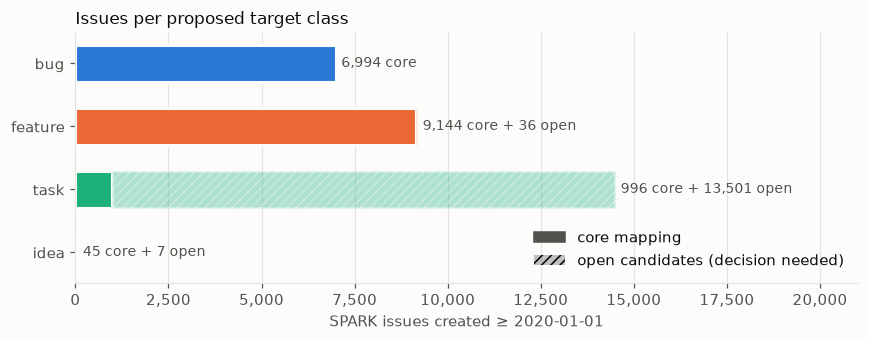

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
y = range(len(CLASSES))[::-1]
core_n = class_volume["core issues"].values
open_n = class_volume["core + open"].values - core_n
for yi, cls, c, o in zip(y, CLASSES, core_n, open_n):
    color = CLASS_COLORS[cls]
    ax.barh(yi, c, color=color, height=0.6, edgecolor=SURFACE, linewidth=2)
    ax.barh(yi, o, left=c, color=color, alpha=0.35, hatch="////", height=0.6, edgecolor=SURFACE, linewidth=2)
    ax.text(c + o + 150, yi, f"{c:,} core" + (f" + {o:,} open" if o else ""), va="center", color=INK2, fontsize=9)
ax.set_yticks(list(y), CLASSES)
ax.set_xlim(0, (core_n + open_n).max() * 1.45)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("SPARK issues created ≥ 2020-01-01")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=INK2), Patch(facecolor=INK2, alpha=0.35, hatch="////")],
          labels=["core mapping", "open candidates (decision needed)"], loc="lower right")
ax.set_title("Issues per proposed target class", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_class_volume.png", bbox_inches="tight")
plt.show()

## 2. Text length per issuetype

Words = whitespace tokens. Description statistics (`*`) are computed over **non-empty** descriptions only;
the share of empty descriptions is reported separately. Issue types with < 30 issues are omitted.

In [7]:
def text_stats(df: pd.DataFrame) -> pd.Series:
    ne = df[~df.empty_desc]
    return pd.Series({
        "issues": len(df),
        "summary words med": df.summary_words.median(),
        "summary words p90": df.summary_words.quantile(0.9),
        "summary chars med": df.summary_chars.median(),
        "summary chars p90": df.summary_chars.quantile(0.9),
        "desc words med*": ne.desc_words.median(),
        "desc words p90*": ne.desc_words.quantile(0.9),
        "desc chars p90*": ne.desc_chars.quantile(0.9),
        "empty desc %": pct(df.empty_desc.mean()),
    })


major = spark.issuetype.value_counts()
major = major[major >= 30].index
length_by_type = pd.DataFrame({t: text_stats(spark[spark.issuetype == t]) for t in major}).T
length_by_type.loc["Wish (SPARK, all-time)"] = text_stats(wish_spark)
length_by_type.loc["Wish (other ASF)"] = text_stats(wish_other)
show(length_by_type.rename_axis("issuetype"))

| issuetype | issues | summary words med | summary words p90 | summary chars med | summary chars p90 | desc words med* | desc words p90* | desc chars p90* | empty desc % |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Sub-task | 12280 | 7 | 11 | 51 | 77 | 31 | 164 | 1514 | 55.8 |
| Improvement | 8142 | 7 | 12 | 55 | 85 | 47 | 186 | 1599.8 | 30 |
| Bug | 6994 | 9 | 15 | 65 | 104 | 104 | 331 | 4326 | 14.9 |
| New Feature | 1002 | 6 | 11 | 46.5 | 74 | 52 | 203.6 | 1476.5 | 26.3 |
| Task | 996 | 7 | 12 | 54 | 82.5 | 30 | 112.4 | 978.6 | 33.2 |
| Test | 798 | 7 | 11 | 53 | 82 | 36 | 164.2 | 2065.8 | 43.7 |
| Umbrella | 336 | 6 | 9 | 40 | 59 | 43 | 207.7 | 1719.0 | 30.4 |
| Documentation | 309 | 8 | 12 | 56 | 84 | 34 | 122.8 | 989.8 | 20.1 |
| Question | 161 | 9 | 14 | 56 | 96 | 115 | 335.6 | 4422.2 | 1.2 |
| Dependency upgrade | 114 | 5 | 8 | 34 | 54.7 | 14 | 150.0 | 1608.4 | 23.7 |
| Epic | 53 | 6 | 10 | 40 | 67.6 | 59 | 262.6 | 1892.8 | 15.1 |
| Wish | 45 | 8 | 13.6 | 57 | 103.2 | 97.5 | 280.8 | 2422.7 | 2.2 |
| Story | 36 | 8 | 12 | 57.5 | 80.5 | 44 | 262.0 | 1780.6 | 30.6 |
| Wish (SPARK, all-time) | 158 | 7 | 13 | 52 | 79.6 | 79 | 225.8 | 2065.2 | 1.9 |
| Wish (other ASF) | 1500 | 7 | 12 | 49 | 79.1 | 64 | 221 | 2026.5 | 2.8 |

In [8]:
length_by_class = pd.DataFrame({c: text_stats(spark[spark.class_core == c]) for c in CLASSES}).T
length_by_class.loc["idea (SPARK all-time + other ASF)"] = text_stats(pd.concat([wish_spark, wish_other]))
show(length_by_class.rename_axis("class (core mapping)"))

| class (core mapping) | issues | summary words med | summary words p90 | summary chars med | summary chars p90 | desc words med* | desc words p90* | desc chars p90* | empty desc % |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| bug | 6994 | 9 | 15 | 65 | 104 | 104 | 331 | 4326 | 14.9 |
| feature | 9144 | 7 | 12 | 54 | 84 | 48 | 187 | 1575 | 29.6 |
| task | 996 | 7 | 12 | 54 | 82.5 | 30 | 112.4 | 978.6 | 33.2 |
| idea | 45 | 8 | 13.6 | 57 | 103.2 | 97.5 | 280.8 | 2422.7 | 2.2 |
| idea (SPARK all-time + other ASF) | 1658 | 7 | 12 | 49 | 79.3 | 66 | 221.8 | 2031.6 | 2.7 |

## 3. Bug structure (regex / keyword heuristics)

Applied to the **description** of Bug issues (case-insensitive, multiline). Heuristics are deliberately simple;
judge them by the matched / unmatched examples below.

Note: Jira also has structured `Affects Version/s` and `Environment` fields, which were **not** downloaded,
so `version_env` measures only what is written in the description text.

In [9]:
BUG_PATTERNS = {
    "repro_keyword": r"steps? to reproduc|how to reproduc|to reproduce|reproduc(?:e|es|ed|ing|tion|ible)\b|\brepro\b",
    "code_or_snippet": r"\{code|\{noformat|```|^\s*(?:scala|spark-sql|sql|>>)>",
    "expected": r"\bexpect(?:ed|s|ing)?\b|\bshould(?:n't| not)? (?:be|return|work|have|produce|give|succeed|fail|throw|not)\b"
                r"|\bsupposed to\b|\bcorrect (?:result|output|answer|behaviou?r)",
    "actual_explicit": r"\bactual(?:ly)?\b|\binstead\b|\bbut (?:got|gets|get|it|returns?|the result|we get|i get)\b|\bobserved\b"
                       r"|\b(?:returns?|gives?|produces?) (?:a )?(?:wrong|incorrect|null|empty)\b",
    "error_output": r"exception|traceback|stack ?trace|\berror\b|caused by:|^\s*at [a-z]+\.[\w.$]+\(",
    "version_env": r"\b(?:spark|pyspark)\s*(?:version\s*)?[:=]?\s*v?[1-4]\.\d|\bversion\s*[:=]?\s*v?\d+\.\d|\bv?[1-4]\.\d+\.\d+\b"
                   r"|\benvironment\b|(?<![.\w])(?:jdk|java|openjdk)(?:\s+version)?[\s:=]+(?:1\.8|8|11|17|21|25)\b"
                   r"|\bpython\s*(?:version\s*)?[:=]?\s*3\.\d|\bscala\s*2\.1[0-3]|\bhadoop\s*[23]\.\d"
                   r"|\b(?:ubuntu|centos|macos|mac os|windows|rhel|debian|amazon linux)\b|\b(?:emr|databricks|dataproc|hdinsight)\b",
}
# Keyword signals run on prose only (no code blocks / inline code), so compiler & lint output
# such as "E302 expected 2 blank lines" or "';' expected instead of 'if'" does not count.
PROSE_SIGNALS = {"repro_keyword", "expected", "actual_explicit"}
FLAGS = re.IGNORECASE | re.MULTILINE
COMPILED = {k: re.compile(v, FLAGS) for k, v in BUG_PATTERNS.items()}
show(pd.DataFrame({"signal": list(BUG_PATTERNS),
                   "applied to": ["prose" if k in PROSE_SIGNALS else "full description" for k in BUG_PATTERNS],
                   "regex": [f"`{p}`" for p in BUG_PATTERNS.values()]}), index=False)


def signal_text(name: str, description: str) -> str:
    return prose_strict(description) if name in PROSE_SIGNALS else description


bugs = spark[spark.issuetype == "Bug"].copy()
for name, rx in COMPILED.items():
    bugs[name] = bugs.description.map(lambda d, rx=rx, name=name: bool(rx.search(signal_text(name, d))))
bugs["repro_any"] = bugs.repro_keyword | bugs.code_or_snippet
bugs["actual_any"] = bugs.actual_explicit | bugs.error_output
bugs["all_four"] = bugs.repro_any & bugs.expected & bugs.actual_any & bugs.version_env

signals = list(BUG_PATTERNS) + ["repro_any", "actual_any", "all_four"]
ne = bugs[~bugs.empty_desc]
bug_structure = pd.DataFrame({
    "% of non-empty Bug descriptions": [pct(ne[s].mean()) for s in signals],
    "% of all Bugs": [pct(bugs[s].mean()) for s in signals],
}, index=pd.Index(signals, name="signal"))
print(f"Bugs: {len(bugs)}, non-empty descriptions: {len(ne)}")
show(bug_structure)

| signal | applied to | regex |
|---|---|---|
| repro_keyword | prose | `steps? to reproduc\|how to reproduc\|to reproduce\|reproduc(?:e\|es\|ed\|ing\|tion\|ible)\b\|\brepro\b` |
| code_or_snippet | full description | `\{code\|\{noformat\|```\|^\s*(?:scala\|spark-sql\|sql\|>>)>` |
| expected | prose | `\bexpect(?:ed\|s\|ing)?\b\|\bshould(?:n't\| not)? (?:be\|return\|work\|have\|produce\|give\|succeed\|fail\|throw\|not)\b\|\bsupposed to\b\|\bcorrect (?:result\|output\|answer\|behaviou?r)` |
| actual_explicit | prose | `\bactual(?:ly)?\b\|\binstead\b\|\bbut (?:got\|gets\|get\|it\|returns?\|the result\|we get\|i get)\b\|\bobserved\b\|\b(?:returns?\|gives?\|produces?) (?:a )?(?:wrong\|incorrect\|null\|empty)\b` |
| error_output | full description | `exception\|traceback\|stack ?trace\|\berror\b\|caused by:\|^\s*at [a-z]+\.[\w.$]+\(` |
| version_env | full description | `\b(?:spark\|pyspark)\s*(?:version\s*)?[:=]?\s*v?[1-4]\.\d\|\bversion\s*[:=]?\s*v?\d+\.\d\|\bv?[1-4]\.\d+\.\d+\b\|\benvironment\b\|(?<![.\w])(?:jdk\|java\|openjdk)(?:\s+version)?[\s:=]+(?:1\.8\|8\|11\|17\|21\|25)\b\|\bpython\s*(?:version\s*)?[:=]?\s*3\.\d\|\bscala\s*2\.1[0-3]\|\bhadoop\s*[23]\.\d\|\b(?:ubuntu\|centos\|macos\|mac os\|windows\|rhel\|debian\|amazon linux)\b\|\b(?:emr\|databricks\|dataproc\|hdinsight)\b` |

Bugs: 6994, non-empty descriptions: 5949


| signal | % of non-empty Bug descriptions | % of all Bugs |
|---|---:|---:|
| repro_keyword | 14.2 | 12.1 |
| code_or_snippet | 48.7 | 41.4 |
| expected | 18.9 | 16.1 |
| actual_explicit | 20.7 | 17.6 |
| error_output | 42.1 | 35.8 |
| version_env | 28.9 | 24.6 |
| repro_any | 52 | 44.3 |
| actual_any | 54.1 | 46 |
| all_four | 3.4 | 2.9 |

In [10]:
by_year = ne.groupby("year")[["repro_keyword", "repro_any", "expected", "actual_explicit", "actual_any", "version_env", "all_four"]].mean().mul(100).round(1)
by_year.insert(0, "non-empty bugs", ne.groupby("year").size())
show(by_year)

| year | non-empty bugs | repro_keyword | repro_any | expected | actual_explicit | actual_any | version_env | all_four |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 2020 | 1123 | 10.1 | 54.7 | 16.5 | 15 | 51.6 | 26.2 | 1.6 |
| 2021 | 966 | 12.9 | 53.7 | 13 | 14.9 | 50.9 | 33.6 | 2.2 |
| 2022 | 810 | 13.8 | 59.8 | 19.6 | 16.7 | 57.2 | 33.5 | 4.4 |
| 2023 | 785 | 8.3 | 49.2 | 15.8 | 17.2 | 55.2 | 27.4 | 2.7 |
| 2024 | 554 | 11.6 | 53.4 | 21.3 | 18.8 | 54 | 23.5 | 3.1 |
| 2025 | 409 | 11.5 | 46.5 | 21 | 22 | 52.6 | 22 | 3.7 |
| 2026 | 1302 | 24.4 | 46.5 | 25.1 | 35.2 | 56.6 | 30.5 | 5.5 |

In [11]:
def heuristic_examples(name: str, k: int = 5) -> None:
    rng = random.Random(SEED)
    rx = COMPILED[name]
    hit = ne[ne[name]]
    miss = ne[~ne[name]]
    rows = []
    for key in rng.sample(list(hit.key), k):
        d = signal_text(name, hit.loc[hit.key == key, "description"].iat[0])
        m = rx.search(d)
        rows.append({"": "✔ match", "key": key, "matched": f"`{m.group(0).strip()}`", "context / start of description": around(d, m.start(), m.end())})
    for key in rng.sample(list(miss.key), k):
        d = miss.loc[miss.key == key, "description"].iat[0]
        rows.append({"": "✘ no match", "key": key, "matched": "", "context / start of description": one_line(d, 260)})
    display(Markdown(f"#### `{name}`"))
    show(pd.DataFrame(rows), index=False)


for name in BUG_PATTERNS:
    heuristic_examples(name)

#### `repro_keyword`

|  | key | matched | context / start of description |
|---|---|---|---|
| ✔ match | SPARK-59444 | `reproducible` | …n. Once B releases 300 bytes, A should acquire 300 bytes normally. The interleaving is reproducible for both ON_HEAP and OFF_HEAP using Spark MemoryConsumer and TaskMemoryManager. It requir… |
| ✔ match | SPARK-34076 | `reproduced` | …all, when canonicalized plan is compared. The error message looks like: This can be reproduced via: through test. |
| ✔ match | SPARK-31059 | `Steps to reproduc` | …ing columns being grouped together to the same buckets. However, this is not the case. Steps to reproduce: 1. Start spark-shell as follows: bin\spark-shell.cmd --master local[4] --conf spark… |
| ✔ match | SPARK-60752 | `reproduce` | …e DPP subquery's scan 7, and both wrap the same . * prunes only on , so it does not reproduce there. * Reading the scans' before execution avoids the failure. * With AQE on, the que… |
| ✔ match | SPARK-39131 | `repro` | …the build side filter to get added: This issue can be boiled down to this simple repro: Which produces a similar plan, with a and no filters: If we naively ad… |
| ✘ no match | SPARK-38542 |  | At present, UnsafeHashedRelation does not write out numKeys during serialization, so the numKeys of UnsafeHashedRelation obtained by deserialization is equal to 0. The numFields of UnsafeRows returned by UnsafeHashedRelation.keys() are all 0, which can lead t… |
| ✘ no match | SPARK-37668 |  | [This piece of code\|https://github.com/apache/spark/blob/6e45b04db48008fa033b09df983d3bd1c4f790ea/python/pyspark/pandas/frame.py#L3991-L3993] in {{pyspark.pandas.frame}} is going to fail on runtime, when {{is_name_like_tuple}} evaluates to {{True}} {code:pyth… |
| ✘ no match | SPARK-34504 |  | in SPARK-34490, I added a `performCheck` flag to skip analysis check when resolving views. This is due to some view resolution is unnecessary. So we can avoid these unnecessary view resolution and remove the `performCheck` flag. |
| ✘ no match | SPARK-33206 |  | SPARK-21501 changed the spark shuffle index service to be based on memory instead of the number of files. Unfortunately, there's a problem with the calculation which is based on size information provided by `ShuffleIndexInformation`. It is based purely on the… |
| ✘ no match | SPARK-59417 |  | When Spark reads multiline JSON whose root value is an array of structs, {{JacksonParser}} currently materializes the entire array before returning rows. For large arrays, parser-side memory usage therefore grows with the complete document size. Add an opt-in… |

#### `code_or_snippet`

|  | key | matched | context / start of description |
|---|---|---|---|
| ✔ match | SPARK-59682 | `{code` | …ction Save the following as {{repro.scala}} and run it with {{{}spark-shell{}}}: {code:java} import org.apache.spark.sql.Encoderscase class Status(path: String, length: Long,… |
| ✔ match | SPARK-32978 | `{code` | How to reproduce this issue: {code:sql} create table dynamic_partition(i bigint, part bigint) using parquet partitioned by… |
| ✔ match | SPARK-31040 | `{code` | …apache/spark/sql/execution/streaming/MicroBatchExecution.scala] offset log 23615 {code:java} {"myTopic.myTopic.orders":{"2":27531503,"5":27562423,"4":27528794,"1":27514991,"3"… |
| ✔ match | SPARK-38120 | `scala>` | …issue as partition column name is lower case. Below how to reproduce the issue: scala> import org.apache.spark.sql.catalyst.TableIdentifier import org.apache.spark.sql.catalys… |
| ✔ match | SPARK-37222 | `{noformat` | …to the Spark shell. With Spark 3.1.2 and 3.2.0 but not 3.0.1 it will throw an exception: {noformat} case class Nested(b: Boolean, n: Long) case class Table(id: String, nested: Nested) c… |
| ✘ no match | SPARK-36865 |  | There is no PySpark API document of session_window. The docstring of the function also doesn't comply with the numpydoc format. |
| ✘ no match | SPARK-34197 |  | The SessionCatalog.refreshTable() should not invalidate the entry in the relation cache for a table when refreshTable() refreshes a temp view. |
| ✘ no match | SPARK-61521 |  | The batch writer's save and parquet/json/csv/orc/text/xml, and DataStreamWriter.start, reject a path that is not a str (123, a pathlib.Path) while their arguments are extracted, before they put the mode, the options, the format, partitionBy or queryName on th… |
| ✘ no match | SPARK-33133 |  | We have run into an issue where our history server fails to load new applications, and when restarted, fails to load any applications at all. This happens when it encounters invalid rolling event log files. We encounter this with long running streaming applic… |
| ✘ no match | SPARK-61048 |  | In PySpark Connect, {{spark.udf}} is a {{UDFRegistration}} whose {{sparkSession}} is the session, and {{spark.udf.registerJavaFunction(name, javaClassName, returnType)}} sends its return type in the {{JavaUDF}} of the {{RegisterFunction}} command: a DDL strin… |

#### `expected`

|  | key | matched | context / start of description |
|---|---|---|---|
| ✔ match | SPARK-35309 | `expected` | …transform function in combination with an alias, I get an unexpected column name. I expected the inner element to have the name 'struct_alias'. |
| ✔ match | SPARK-31621 | `Expected` | …one more application using the spark-submit command. # Load Spark Master UI again. *Expected Behavior:* Spark Master UI should launch successfully. *Actual Behavior*: Spark Master… |
| ✔ match | SPARK-45631 | `should be` | …iting implementations to implement the method. It seems like abstractmethod annotation should be removed to retain backward compatibility. |
| ✔ match | SPARK-43224 | `should be` | …tly, executor info in standalone master will be removed once decommissioned. The executor should be removed after executor shutdown. |
| ✔ match | SPARK-41242 | `should be` | …main/scala/org/apache/spark/sql/execution/datasources/PartitioningUtils.scala#L66], Spark should be matching the milliseconds fraction just fine. Now this is where it gets more inte… |
| ✘ no match | SPARK-34720 |  | The natural expectation of INSERT * or UPDATE * in MERGE is to assign source columns to target columns of the same name. However, the current logic here generates the assignment by position. https://github.com/apache/spark/commit/7cfd589868b8430bc79e28e4d5470… |
| ✘ no match | SPARK-33482 |  | Sample query: {noformat} spark.read.parquet("tbl").createOrReplaceTempView("tbl") spark.read.parquet("lookup").createOrReplaceTempView("lookup") sql(""" select tbl.col1, fk1, fk2 from tbl, lookup l1, lookup l2 where fk1 = l1.key and fk2 = l2.key """).explain … |
| ✘ no match | SPARK-60967 |  | In PySpark Connect, a value of a user-defined type that a DataFrame collects is deserialized by its UDT, and {{dtypes}} gives the UDT's {{simpleString()}}. With {{df = spark.sql("SELECT array(1.5D, 2.0D) AS a").select(array_to_vector("a").alias("vec"))}} of {… |
| ✘ no match | SPARK-32988 |  | With Spark 2.3 spark.sharedState.externalCatalog used to give an object of ExternalCatalog which was actually an instance of HiveExternalCatalog With Spark 2.4 spark.sharedState.externalCatalog gives an object of ExternalCatalogWithListener which has HiveExte… |
| ✘ no match | SPARK-50034 |  | In {{{}Executor.scala{}}}, an exception is considered fatal (determined by isFatalError()) if any exception in the chain (or its causes) is fatal. This behavior is controlled by the {{spark.executor.killOnFatalError.depth}} config, which limits the depth to w… |

... (2 outputs left out)

#### `error_output`

|  | key | matched | context / start of description |
|---|---|---|---|
| ✔ match | SPARK-33813 | `exception` | …ince version 7.0. The JDBC data source lacks mappings for these types which results in an exception below. It seems that a mapping in MsSqlServerDialect.getCatalystType that maps -157 and -… |
| ✔ match | SPARK-31247 | `Error` | …/amplab.cs.berkeley.edu/jenkins/job/SparkPullRequestBuilder/120336/testReport/ {code} Error Message org.scalatest.exceptions.TestFailedException: Error adding data: Timeout after… |
| ✔ match | SPARK-40036 | `Exception` | {code:java} @Test public void testHasNextAndNextAfterIteratorClose() throws Exception { String prefix = "test_db_iter_close."; String suffix = ".ldb"; File path = Fil… |
| ✔ match | SPARK-38931 | `exception` | …if the 1st checkpoint is empty, it will not create the root dfs directory, which leads to exception below: {code:java} File /private/var/folders/rk/wyr101_562ngn8lp7tbqt7_00000gp/T/sp… |
| ✔ match | SPARK-38087 | `exception` | …frame on that column. df4 = df2.select(df2.firstname, df2.lastname) --> throws analysis exception df4.show() However drop will not let you drop the said column. Scenario t… |
| ✘ no match | SPARK-33417 |  | This PR intends to fix the behaviour of query filters in TPCDSQueryBenchmark. We can use an option --query-filter for selecting TPCDS queries to run, e.g., --query-filter q6,q8,q13. But, the current master has a weird behaviour about the option. For example, … |
| ✘ no match | SPARK-60240 |  | PR that fixes this - [https://github.com/apache/spark/pull/59507] Bug description - all regarding {{{}tuple_sketch_agg{}}}: * spark GROUP BY returns a different answer depending on if it ran on one task (COMPLETE agg mode) or in multiple tasks. When running o… |
| ✘ no match | SPARK-32635 |  | When pyspark.sql.functions.lit() function is used with dataframe cache, it returns wrong result eg:lit() function with cache() function. ----------------------------------- {code:java} from pyspark.sql import Row from pyspark.sql import functions as F df_1 = … |
| ✘ no match | SPARK-57200 |  | ArrayJoin.doGenCode silently returns NULL for every row when the third argument (nullReplacement) is a non-foldable column, the plan is fused in Whole-Stage Codegen (WSCG), and an upstream Filter with IsNotNull(array) has tightened the array (and/or delimiter… |
| ✘ no match | SPARK-60373 |  | The bug is an ancient one introduced in Spark 3.2.0. Structured Streaming outer joins underreport {{{}StateOperatorProgress.numRowsRemoved{}}}. State removed while producing unmatched outer-join output is not counted. Left/right outer joins omit removals from… |

#### `version_env`

|  | key | matched | context / start of description |
|---|---|---|---|
| ✔ match | SPARK-53972 | `version 4.0` | …ession in Apache Spark's streaming recentProgress method in python notebook starting from version 4.0.0. The time required to fetch recentProgress increases substantially as the number of pro… |
| ✔ match | SPARK-33024 | `Scala 2.13` | …DF should not fail on WrappedArray` in s.sql.UDFSuite exposed a codegen fallback issue in Scala 2.13 as follow: {code:java} - SPARK-32459: UDF should not fail on WrappedArray *** FAILED **… |
| ✔ match | SPARK-31113 | `Spark 3.0` | …02519201], {quote}Tableau and PowerBI, which use the Simba ODBC driver, do not work with Spark 3.0 with Hive 2.3. When we switch to Hive 2.3 profile, Simba driver assumes that {{SHOW VI… |
| ✔ match | SPARK-60647 | `python3.1` | …result = np.exp(t0['c0']) ^^^^^^^^^^^^^^^^ File "/opt/conda/envs/lib/python3.11/site-packages/pyspark/pandas/base.py", line 555, in __array_ufunc__ result = numpy_… |
| ✔ match | SPARK-37315 | `Scala 2.13` | …own from the following part of the test "pipeline read/write events" in MLEventSuite when Scala 2.13 is used. {code} events.map(JsonProtocol.sparkEventToJson).foreach { event => assert(… |
| ✘ no match | SPARK-41780 |  | {code:scala} scala> spark.sql("select regexp_replace('', '[a\\\\d]{0,2}', 'x')").show +----------------------------------+ \|regexp_replace(, [a\d]\{0,2}, x, 1)\| +----------------------------------+ \| x\| +----------------------------------+ scala> spark.sql("s… |
| ✘ no match | SPARK-40140 |  | Hi All, We noticed that the SQL information REST API implemented in https://issues.apache.org/jira/browse/SPARK-27142 does not return back SQL queries which are currently running. We can only see queries which are completed/failed. As far as I can see, this s… |
| ✘ no match | SPARK-35597 |  | When using a JDBC data source, the "With" CTE function generates invalid SQL syntax when called In the below example you can assume that SOURCE_CONNECTION, SQL_DRIVER and TABLE are all correctly defined. SQLServerException: Incorrect syntax near the keyword '… |
| ✘ no match | SPARK-34013 |  | {code:java} rdd.mapPartitions(par => { val jedis: Jedis = AdJedisPoolUtils.getJedis jedis.select(4) val res: Iterator[(((String, String), (String, String, String, String, String, String, String, String, String)), String)] = par.map(data =>{ println(data._2._1… |
| ✘ no match | SPARK-33342 |  | In the threadDump page, when a thread is blocked by anther thread, the blocking thread name and url were both displayed incorrect, causing the url to fail to jump. such as *Thread 73* but shows `*Thread some(73)*` |

## 4. Task vs Sub-task, and SPARK Wish vs other-ASF Wish

Top terms = share of issues whose text contains the term (document frequency), after removing stop-words,
URLs and `{code}`/`{noformat}` blocks.

In [12]:
def compare(groups: dict[str, pd.DataFrame]) -> None:
    stats = pd.DataFrame({name: text_stats(df) for name, df in groups.items()}).T
    stats["has code block %"] = [pct(df.description.str.contains(r"\{code|\{noformat|```").mean()) for df in groups.values()]
    show(stats.rename_axis("group"))

    for field, label in [("summary", "summary"), ("description", "description (prose)")]:
        cols = {}
        for name, df in groups.items():
            texts = df[field].map(prose) if field == "description" else df[field]
            dfreq = doc_freq(texts)
            cols[name] = [f"{t} ({pct(n / len(df))}%)" for t, n in dfreq.most_common(20)]
        display(Markdown(f"**Top-20 terms in {label}**"))
        show(pd.DataFrame(cols, index=pd.RangeIndex(1, 21, name="rank")))

    for name, df in groups.items():
        sample = df.sample(5, random_state=SEED)
        display(Markdown(f"**5 random examples — {name}**"))
        show(pd.DataFrame({
            "key": sample.key,
            "summary": sample.summary.map(lambda s: one_line(s, 120)),
            "description (start)": sample.description.map(lambda s: one_line(s, 200) or "∅ (empty)"),
        }), index=False)


compare({"Task": spark[spark.issuetype == "Task"], "Sub-task": spark[spark.issuetype == "Sub-task"]})

| group | issues | summary words med | summary words p90 | summary chars med | summary chars p90 | desc words med* | desc words p90* | desc chars p90* | empty desc % | has code block % |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Task | 996 | 7 | 12 | 54 | 82.5 | 30 | 112.4 | 978.6 | 33.2 | 7.2 |
| Sub-task | 12280 | 7 | 11 | 51 | 77 | 31 | 164 | 1514 | 55.8 | 9.6 |

**Top-20 terms in summary**

| rank | Task | Sub-task |
|---:|---|---|
| 1 | add (18.7%) | support (13.4%) |
| 2 | support (10.6%) | add (11.2%) |
| 3 | state (10.1%) | spark (8.5%) |
| 4 | spark (9.5%) | upgrade (7.8%) |
| 5 | streaming (7.0%) | use (6.1%) |
| 6 | fix (6.9%) | fix (6.0%) |
| 7 | remove (5.8%) | error (5.2%) |
| 8 | api (5.6%) | sql (4.6%) |
| 9 | python (5.3%) | test (4.4%) |
| 10 | connect (4.9%) | python (4.1%) |
| 11 | sql (4.7%) | type (3.8%) |
| 12 | error (4.5%) | pyspark (3.8%) |
| 13 | scala (4.2%) | connect (3.5%) |
| 14 | test (4.1%) | tests (3.5%) |
| 15 | pyspark (3.9%) | remove (3.3%) |
| 16 | store (3.9%) | pandas (3.1%) |
| 17 | rocksdb (3.4%) | enable (3.0%) |
| 18 | use (3.2%) | dataframe (3.0%) |
| 19 | data (3.1%) | java (2.8%) |
| 20 | source (3.0%) | implement (2.7%) |

**Top-20 terms in description (prose)**

| rank | Task | Sub-task |
|---:|---|---|
| 1 | spark (18.5%) | spark (13.2%) |
| 2 | add (13.3%) | add (6.6%) |
| 3 | state (9.2%) | sql (6.2%) |
| 4 | support (7.8%) | support (5.6%) |
| 5 | query (7.3%) | error (5.4%) |
| 6 | sql (6.8%) | type (4.5%) |
| 7 | error (6.5%) | test (4.2%) |
| 8 | streaming (6.0%) | use (4.2%) |
| 9 | use (5.7%) | tests (3.8%) |
| 10 | api (5.2%) | data (3.4%) |
| 11 | python (4.5%) | time (3.2%) |
| 12 | using (4.4%) | example (3.1%) |
| 13 | version (4.2%) | scala (2.9%) |
| 14 | change (4.1%) | table (2.9%) |
| 15 | data (4.0%) | class (2.8%) |
| 16 | scala (3.9%) | using (2.8%) |
| 17 | store (3.9%) | pyspark (2.7%) |
| 18 | users (3.8%) | python (2.7%) |
| 19 | after (3.8%) | pandas (2.7%) |
| 20 | source (3.8%) | types (2.6%) |

**5 random examples — Task**

| key | summary | description (start) |
|---|---|---|
| SPARK-54761 | Throw unsupportedTableOperationError for table constraint operation on dsv1/hms table | ∅ (empty) |
| SPARK-59533 | Remove deprecated `enable` keys from Helm `values.yaml` in chart 2.0.0 | ∅ (empty) |
| SPARK-37050 | Update conda installation instructions | Improve conda installation documentation, as discussed [here\|https://github.com/apache/spark-website/pull/361#issuecomment-945660978]. |
| SPARK-49758 | Allow adding Scala UDFs in UDFRegistration | In https://issues.apache.org/jira/browse/SPARK-49122 and its corresponding PR [https://github.com/apache/spark/pull/48120,] we added a new user-facing API `UDFRegistration.registerJava`. However this… |
| SPARK-47004 | Increase Scala client test coverage | ∅ (empty) |

**5 random examples — Sub-task**

| key | summary | description (start) |
|---|---|---|
| SPARK-47083 | Upgrade `commons-codec` to 1.16.1 | ∅ (empty) |
| SPARK-38750 | Test the error class: SECOND_FUNCTION_ARGUMENT_NOT_INTEGER | Add a test for the error classes *SECOND_FUNCTION_ARGUMENT_NOT_INTEGER* to QueryCompilationErrorsSuite. The test should cover the exception throw in QueryCompilationErrors: {code:scala} def secondArg… |
| SPARK-31857 | Support Azure SQLDB Kerberos login in JDBC connector | ∅ (empty) |
| SPARK-49939 | Codegen Support for json_object_keys (by Invoke & RuntimeReplaceable) | ∅ (empty) |
| SPARK-47775 | Support remaining scalar types in the variant spec. | ∅ (empty) |

In [13]:
groups = {
    "Wish SPARK (all-time)": wish_spark,
    "Wish SPARK (≥2020)": wish_spark[wish_spark.year >= 2020],
    "Wish other ASF": wish_other,
}
compare({k: v for k, v in groups.items() if k != "Wish SPARK (≥2020)"})
show(pd.DataFrame({k: text_stats(v) for k, v in groups.items()}).T.rename_axis("group"))
show(wish_spark.year.value_counts().sort_index().rename("SPARK Wish issues").rename_axis("year").to_frame().T, index=False)

| group | issues | summary words med | summary words p90 | summary chars med | summary chars p90 | desc words med* | desc words p90* | desc chars p90* | empty desc % | has code block % |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Wish SPARK (all-time) | 158 | 7 | 13 | 52 | 79.6 | 79 | 225.8 | 2065.2 | 1.9 | 23.4 |
| Wish other ASF | 1500 | 7 | 12 | 49 | 79.1 | 64 | 221 | 2026.5 | 2.8 | 17.4 |

**Top-20 terms in summary**

| rank | Wish SPARK (all-time) | Wish other ASF |
|---:|---|---|
| 1 | spark (29.7%) | support (9.6%) |
| 2 | sql (11.4%) | add (9.3%) |
| 3 | add (10.1%) | apache (4.3%) |
| 4 | support (7.6%) | use (3.6%) |
| 5 | allow (7.0%) | version (3.1%) |
| 6 | pyspark (5.7%) | release (2.9%) |
| 7 | api (5.1%) | allow (2.5%) |
| 8 | dataframe (5.1%) | file (2.3%) |
| 9 | public (4.4%) | create (2.3%) |
| 10 | name (3.8%) | java (2.3%) |
| 11 | hive (3.2%) | update (2.1%) |
| 12 | create (3.2%) | remove (2.0%) |
| 13 | function (3.2%) | python (1.9%) |
| 14 | file (3.2%) | client (1.9%) |
| 15 | mode (3.2%) | api (1.7%) |
| 16 | table (3.2%) | camel (1.7%) |
| 17 | type (3.2%) | server (1.7%) |
| 18 | executor (3.2%) | wish (1.7%) |
| 19 | running (2.5%) | documentation (1.6%) |
| 20 | driver (2.5%) | fix (1.6%) |

**Top-20 terms in description (prose)**

| rank | Wish SPARK (all-time) | Wish other ASF |
|---:|---|---|
| 1 | spark (62.7%) | use (22.1%) |
| 2 | use (24.1%) | using (17.4%) |
| 3 | data (22.8%) | apache (14.0%) |
| 4 | sql (22.2%) | add (13.3%) |
| 5 | using (18.4%) | support (12.9%) |
| 6 | example (16.5%) | version (11.9%) |
| 7 | used (14.6%) | file (10.3%) |
| 8 | set (14.6%) | used (9.9%) |
| 9 | user (13.9%) | example (9.9%) |
| 10 | run (13.3%) | java (9.7%) |
| 11 | time (13.3%) | time (9.5%) |
| 12 | add (12.7%) | data (8.7%) |
| 13 | however (12.7%) | possible (8.6%) |
| 14 | instead (12.7%) | however (8.1%) |
| 15 | possible (12.7%) | user (8.0%) |
| 16 | support (12.7%) | project (7.9%) |
| 17 | method (12.0%) | want (7.7%) |
| 18 | work (11.4%) | files (7.5%) |
| 19 | apache (11.4%) | users (7.4%) |
| 20 | want (10.8%) | able (7.3%) |

**5 random examples — Wish SPARK (all-time)**

| key | summary | description (start) |
|---|---|---|
| SPARK-38554 | Dataframe API: withColumn "comment" parameter | I often find that the right time to document a column in a dataframe is when I create it. It would be nice if withColumn took an optional comment parameter, then one could write e.g. {code:java} df =… |
| SPARK-13085 | Add scalastyle command used in build testing | As an occasional or new contributor, it is easy to screw up scala style. But looking at the output logs (for example https://amplab.cs.berkeley.edu/jenkins/job/SparkPullRequestBuilder/50300/consoleFu… |
| SPARK-42645 | Introduce feature to allow for function caching across input rows. | Introduce the ability to make functions cachable across input rows. I'm imagining this function to work similarly to python's [functools.cache\|https://docs.python.org/3/library/functools.html#functoo… |
| SPARK-55569 | Collapse non-matching pivot column values in fast-path firstAgg | When pivoting on a set of values, this is potentially a subset of all values. Nonetheless, there's no predicate pushdown to the source. {code:sql} SELECT * FROM person PIVOT ( SUM(age) AS a, AVG(clas… |
| SPARK-26417 | Make comments for states available for logging | When add an extra `SparkListener`, it would be very useful (in production applications) to get the description of a state. For now it only available as comments in code. As suggestion it could be mov… |

**5 random examples — Wish other ASF**

| key | summary | description (start) |
|---|---|---|
| PDFBOX-5235 | When extracting text from pdf, spaces are replaced with other characters | hello I am trying to extract text from a pdf. However, when I extract the text using PDFTextStripper, the spaces in the text of the pdf are replaced with strange characters. Is there any way to preve… |
| PHOENIX-6285 | CDH parcels not found | Why does the download URL of the CDH parcels no longer exist? |
| CALCITE-5973 | Parsing DDL error message is inaccurate | When i parse the following DDL statement: {code:java} // code placeholder reate table t ( a int, b varchar) with('key' = 'value') {code} where the create keyword lacks the initial letter c The parse … |
| NUTCH-3003 | Consider integration testing in a Dockerized mini-hadoop cluster via testcontainers? | I don't think I'll have the time to do this any time soon, but this might help lead the way: https://github.com/ooraini/testcontainers-hdfs We've started using testcontainers in unit tests on the Tik… |
| ZOOKEEPER-4715 | Verify file size and position in testGetCurrentLogSize. | This is pre-PR for ZOOKEEPER-4714. In ZOOKEEPER-4714, we maintain fileSize and filePosition ourselves and we want our values to match the original values. Therefore, we added checks for fileSize and … |

| group | issues | summary words med | summary words p90 | summary chars med | summary chars p90 | desc words med* | desc words p90* | desc chars p90* | empty desc % |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Wish SPARK (all-time) | 158 | 7 | 13 | 52 | 79.6 | 79 | 225.8 | 2065.2 | 1.9 |
| Wish SPARK (≥2020) | 45 | 8 | 13.6 | 57 | 103.2 | 97.5 | 280.8 | 2422.7 | 2.2 |
| Wish other ASF | 1500 | 7 | 12 | 49 | 79.1 | 64 | 221 | 2026.5 | 2.8 |

| 2014 | 2015 | 2016 | 2017 | 2018 | 2019 | 2020 | 2021 | 2022 | 2023 | 2024 | 2025 | 2026 |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 13 | 29 | 19 | 16 | 14 | 22 | 6 | 5 | 10 | 3 | 13 | 5 | 3 |

### Class-leakage check: project-specific terms in `wish_other`

If `idea` training examples come from other projects while the other classes come from SPARK, a classifier can learn
"non-Spark vocabulary ⇒ idea". Below: terms much more frequent in `wish_other` than in SPARK
(smoothed log-odds of document frequency, df ≥ 15 in wish_other), with the project that contributes most of them.

In [14]:
def text_of(df: pd.DataFrame) -> pd.Series:
    return df.summary + " \n " + df.description.map(prose)


wo_terms = [terms(t) for t in text_of(wish_other)]
sp_df = doc_freq(text_of(spark))
wo_df = Counter(t for ts in wo_terms for t in ts)
n_o, n_s = len(wish_other), len(spark)

rows = []
for term, c in wo_df.items():
    if c < 15:
        continue
    s = sp_df.get(term, 0)
    log_odds = math.log((c + 0.5) / (n_o - c + 0.5)) - math.log((s + 0.5) / (n_s - s + 0.5))
    projects = Counter(p for p, ts in zip(wish_other.project, wo_terms) if term in ts)
    top_p, top_c = projects.most_common(1)[0]
    rows.append({"term": term, "wish_other df %": pct(c / n_o), "SPARK df %": pct(s / n_s), "log-odds": round(log_odds, 2),
                 "top project (share of term's issues)": f"{top_p} ({pct(top_c / c)}%)", "projects": len(projects)})
leak = pd.DataFrame(rows).sort_values("log-odds", ascending=False)
show(leak.head(30), index=False)

| term | wish_other df % | SPARK df % | log-odds | top project (share of term's issues) | projects |
|---|---:|---:|---:|---|---:|
| guacamole | 3.1 | 0 | 7.6 | GUACAMOLE (100.0%) | 1 |
| nifi | 1.6 | 0 | 7.0 | NIFI (95.8%) | 2 |
| tika | 1.5 | 0 | 6.9 | TIKA (91.3%) | 3 |
| cxf | 1.3 | 0 | 6.8 | CXF (85.0%) | 4 |
| pdfbox | 1.3 | 0 | 6.7 | PDFBOX (89.5%) | 3 |
| kylin | 1.2 | 0 | 6.7 | KYLIN (94.4%) | 2 |
| activemq | 1.1 | 0 | 6.6 | ARTEMIS (41.2%) | 4 |
| rdp | 1.1 | 0 | 6.5 | GUACAMOLE (100.0%) | 1 |
| camel | 2.8 | 0 | 5.6 | CAMEL (90.5%) | 4 |
| lucene | 1.1 | 0 | 5.5 | LUCENE (47.1%) | 7 |
| solr | 1.8 | 0 | 5.5 | SOLR (77.8%) | 6 |
| calcite | 1.5 | 0 | 5.3 | CALCITE (87.0%) | 2 |
| wish | 5.1 | 0 | 4.8 | CAUSEWAY (28.9%) | 31 |
| processors | 1.3 | 0 | 4.6 | NIFI (75.0%) | 5 |
| leader | 1.1 | 0 | 4.3 | RATIS (18.8%) | 9 |
| admin | 1.5 | 0 | 4.0 | GUACAMOLE (17.4%) | 14 |
| pdf | 1.9 | 0 | 3.9 | PDFBOX (79.3%) | 4 |
| wondering | 2 | 0 | 3.7 | HORN (26.7%) | 17 |
| spring | 1.2 | 0 | 3.7 | CXF (16.7%) | 12 |
| broker | 1.3 | 0 | 3.7 | ARTEMIS (35.0%) | 6 |
| everyone | 1.3 | 0 | 3.7 | HORN (42.1%) | 9 |
| flink | 1.1 | 0 | 3.7 | HUDI (17.6%) | 10 |
| internet | 1.1 | 0 | 3.4 | HORN (47.1%) | 9 |
| thank | 3.2 | 0.1 | 3.2 | HORN (16.7%) | 26 |
| nice | 6.1 | 0.3 | 3.1 | ARROW (12.0%) | 38 |
| hbase | 1.1 | 0.1 | 3.1 | HBASE (41.2%) | 8 |
| connections | 1.8 | 0.1 | 3.0 | GUACAMOLE (51.9%) | 11 |
| thanks | 6.7 | 0.4 | 3.0 | GUACAMOLE (8.0%) | 57 |
| website | 2.3 | 0.1 | 2.9 | HORN (22.9%) | 22 |
| processor | 1.9 | 0.1 | 2.9 | NIFI (71.4%) | 9 |

In [15]:
def own_project_tokens(row) -> set[str]:
    name_words = {w.lower() for w in re.findall(r"[A-Za-z][A-Za-z0-9]+", row.project_name)} - {"apache", "the", "project"}
    return name_words | {row.project.lower()}


wish_other["mentions_own_project"] = [
    bool(own_project_tokens(r) & set(re.findall(r"[a-z0-9]+", (r.summary + " " + r.description).lower())))
    for r in wish_other.itertuples()
]
spark_word = re.compile(r"\bspark\b|pyspark", re.I)
leak_summary = pd.DataFrame({
    "corpus": ["SPARK issues ≥2020", "SPARK Wish (all-time)", "Wish other ASF", "Wish other ASF (non-SPARK only)"],
    "% mention 'spark'/'pyspark'": [
        pct(text_of(spark).str.contains(spark_word).mean()),
        pct(text_of(wish_spark).str.contains(spark_word).mean()),
        pct(text_of(wish_other).str.contains(spark_word).mean()),
        pct(text_of(wish_other[wish_other.project != "SPARK"]).str.contains(spark_word).mean()),
    ],
    "% mention own project key/name": ["n/a", "n/a", pct(wish_other.mentions_own_project.mean()),
                                       pct(wish_other[wish_other.project != "SPARK"].mentions_own_project.mean())],
})
show(leak_summary, index=False)
top_projects = wish_other.project.value_counts()
print(f"wish_other: {len(top_projects)} projects; top-10 cover {pct(top_projects.head(10).sum() / len(wish_other))}% of issues")
show(top_projects.head(15).rename("issues").rename_axis("project").to_frame().T, index=False)

| corpus | % mention 'spark'/'pyspark' | % mention own project key/name |
|---|---:|---|
| SPARK issues ≥2020 | 40 | n/a |
| SPARK Wish (all-time) | 72.8 | n/a |
| Wish other ASF | 3.6 | 63.3 |
| Wish other ASF (non-SPARK only) | 1.5 | 63 |

wish_other: 190 projects; top-10 cover 36.3% of issues


| ARROW | GUACAMOLE | KAFKA | CALCITE | CAMEL | NIFI | HDFS | SPARK | BEAM | IOTDB | TIKA | PDFBOX | SOLR | KYLIN | GEODE |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 103 | 71 | 59 | 55 | 50 | 49 | 44 | 41 | 38 | 34 | 33 | 33 | 32 | 28 | 28 |

## 5. Duplicate links

Jira link type `Duplicate` has `outward = "duplicates"` and `inward = "is duplicated by"`.
On issue **X**: a link with `outwardIssue = Y` reads "X duplicates Y" → X is the duplicate, Y the original;
a link with `inwardIssue = Y` reads "X is duplicated by Y" → Y is the duplicate, X the original.
The same link appears on both issues when both are in the dataset.

In [16]:
spark_keys = set(spark.key)
summary_of = dict(zip(spark.key, spark.summary))
resolution_of = dict(zip(spark.key, spark.resolution))
type_of = dict(zip(spark.key, spark.issuetype))

link_rows = []
for key, links in zip(spark.key, spark.issuelinks):
    for link in links:
        if link["type"]["name"] != "Duplicate":
            continue
        if "outwardIssue" in link:
            other = link["outwardIssue"]
            dup, orig, side = key, other["key"], "outwardIssue"
        else:
            other = link["inwardIssue"]
            dup, orig, side = other["key"], key, "inwardIssue"
        summary_of.setdefault(other["key"], other.get("fields", {}).get("summary", ""))
        link_rows.append({"seen_on": key, "side": side, "inward": link["type"]["inward"], "outward": link["type"]["outward"],
                          "link_id": link["id"], "duplicate": dup, "original": orig})
links = pd.DataFrame(link_rows)
show(links.groupby(["side", "inward", "outward"]).size().rename("link entries").reset_index(), index=False)

pairs = links.drop_duplicates("link_id")[["link_id", "duplicate", "original"]]
pairs = pairs.assign(dup_in=pairs.duplicate.isin(spark_keys), orig_in=pairs.original.isin(spark_keys))
dup_stats = {
    "Duplicate link entries (both sides counted)": len(links),
    "Unique Duplicate links (pairs)": len(pairs),
    "Issues with ≥1 Duplicate link": links.seen_on.nunique(),
    "Pairs with both issues in dataset": int((pairs.dup_in & pairs.orig_in).sum()),
    "Originals inside dataset": int(pairs.orig_in.sum()),
    "Originals outside dataset (older or other project)": int((~pairs.orig_in).sum()),
    "  …of which non-SPARK originals": int((~pairs.original.str.startswith("SPARK-")).sum()),
    "Duplicates inside dataset": int(pairs.dup_in.sum()),
}
show(pd.Series(dup_stats, name="count").rename_axis("metric").to_frame())
print(f"Originals inside dataset: {pct(pairs.orig_in.mean())}% of pairs")

| side | inward | outward | link entries |
|---|---|---|---:|
| inwardIssue | is duplicated by | duplicates | 429 |
| outwardIssue | is duplicated by | duplicates | 458 |

| metric | count |
|---|---:|
| Duplicate link entries (both sides counted) | 887 |
| Unique Duplicate links (pairs) | 484 |
| Issues with ≥1 Duplicate link | 805 |
| Pairs with both issues in dataset | 403 |
| Originals inside dataset | 429 |
| Originals outside dataset (older or other project) | 55 |
|   …of which non-SPARK originals | 3 |
| Duplicates inside dataset | 458 |

Originals inside dataset: 88.6% of pairs


In [17]:
# Is the link direction consistent with the resolution field?
dup_side = pairs[pairs.dup_in].duplicate.map(resolution_of)
orig_side = pairs[pairs.orig_in].original.map(resolution_of)
consistency = pd.DataFrame({
    "duplicate side": dup_side.value_counts(normalize=True).mul(100).round(1),
    "original side": orig_side.value_counts(normalize=True).mul(100).round(1),
}).fillna(0).sort_values("duplicate side", ascending=False).head(8)
display(Markdown("**Resolution of each side of a Duplicate pair (% of pairs where that side is in the dataset)**"))
show(consistency.rename_axis("resolution"))

res_dup = spark[spark.resolution == "Duplicate"]
with_link = res_dup.key.isin(links.seen_on)
print(f"Issues resolved as 'Duplicate': {len(res_dup)}; with a Duplicate link: {with_link.sum()} ({pct(with_link.mean())}%)")

both = pairs[pairs.dup_in & pairs.orig_in]
display(Markdown("**Issue type of duplicate (rows) vs original (columns), pairs with both sides in dataset**"))
xt = pd.crosstab(both.duplicate.map(type_of), both.original.map(type_of))
top_types = ["Bug", "Improvement", "New Feature", "Sub-task", "Task"]
show(xt.reindex(index=top_types, columns=top_types, fill_value=0).rename_axis("duplicate \\ original"))

**Resolution of each side of a Duplicate pair (% of pairs where that side is in the dataset)**

| resolution | duplicate side | original side |
|---|---:|---:|
| Duplicate | 75.8 | 18.4 |
| Fixed | 17.2 | 66.9 |
| Unresolved | 5.5 | 10.5 |
| Cannot Reproduce | 0.4 | 0.2 |
| Incomplete | 0.4 | 0.5 |
| Invalid | 0.2 | 1.2 |
| Resolved | 0.2 | 0 |
| Won't Fix | 0.2 | 0.9 |

Issues resolved as 'Duplicate': 669; with a Duplicate link: 405 (60.5%)


**Issue type of duplicate (rows) vs original (columns), pairs with both sides in dataset**

| duplicate \ original | Bug | Improvement | New Feature | Sub-task | Task |
|---|---:|---:|---:|---:|---:|
| Bug | 102 | 14 | 0 | 24 | 5 |
| Improvement | 14 | 46 | 3 | 29 | 1 |
| New Feature | 1 | 2 | 5 | 4 | 0 |
| Sub-task | 5 | 6 | 0 | 95 | 0 |
| Task | 1 | 1 | 4 | 0 | 2 |

In [18]:
sample = pairs[pairs.duplicate.map(lambda k: bool(summary_of.get(k))) & pairs.original.map(lambda k: bool(summary_of.get(k)))]
sample = sample.sample(5, random_state=SEED)
for r in sample.itertuples():
    print(f"{r.duplicate}  {one_line(summary_of[r.duplicate], 90)}\n   → {r.original}  {one_line(summary_of[r.original], 90)}\n")

SPARK-49774  Upgrade guava to 33.3.1-jre
   → SPARK-50468  Upgrade Guava to 33.3.1-jre

SPARK-60588  Share nested struct field names in the Rust Spark Connect client
   → SPARK-60585  Share immutable field names across decoded rows in the Rust Spark Connect client

SPARK-35307  Upgrade netty to netty-4.1.63.Final
   → SPARK-35132  Upgrade netty-all to 4.1.63.Final

SPARK-56902  Spread NULL outer join keys across shuffle partitions
   → SPARK-56899  Spread NULL outer join keys across shuffle partitions

SPARK-41176  Assign a name to the error class _LEGACY_ERROR_TEMP_1042
   → SPARK-41147  Assign a name to the legacy error class _LEGACY_ERROR_TEMP_1042



## 6. Resolution × target class

Columns are issue types grouped by proposed class; Wish columns come from the two extra Wish files.
Values are column percentages (counts in the second table).

In [19]:
FOCUS = ["Fixed", "Done", "Won't Fix", "Won't Do", "Later", "Not A Problem", "Invalid", "Incomplete", "Duplicate", "Unresolved"]
cols = {
    "bug: Bug": spark[spark.issuetype == "Bug"],
    "feature: New Feature": spark[spark.issuetype == "New Feature"],
    "feature: Improvement": spark[spark.issuetype == "Improvement"],
    "task: Task": spark[spark.issuetype == "Task"],
    "task?: Sub-task": spark[spark.issuetype == "Sub-task"],
    "idea: Wish SPARK all-time": wish_spark,
    "idea: Wish other ASF": wish_other,
}
res_counts = pd.DataFrame({
    name: df.resolution.where(df.resolution.isin(FOCUS), "Other").value_counts() for name, df in cols.items()
}).reindex(FOCUS + ["Other"]).fillna(0).astype(int)
res_pct = (100 * res_counts / res_counts.sum()).round(1)
res_counts.loc["Total"] = res_counts.sum()
show(res_pct.rename_axis("resolution (% of column)"))
show(res_counts.rename_axis("resolution (count)"))

| resolution (% of column) | bug: Bug | feature: New Feature | feature: Improvement | task: Task | task?: Sub-task | idea: Wish SPARK all-time | idea: Wish other ASF |
|---|---:|---:|---:|---:|---:|---:|---:|
| Fixed | 60.1 | 56.4 | 66.3 | 76.4 | 88.5 | 10.8 | 25.9 |
| Done | 0.1 | 1 | 0.3 | 0.7 | 0.4 | 0 | 1.5 |
| Won't Fix | 1.2 | 1.8 | 1.9 | 0.8 | 0.8 | 16.5 | 3.2 |
| Won't Do | 0.1 | 0.5 | 0.4 | 0.6 | 0.3 | 0 | 1.6 |
| Later | 0.1 | 0.3 | 0.1 | 0.1 | 0.1 | 0.6 | 0.1 |
| Not A Problem | 2.7 | 0.6 | 0.9 | 0.8 | 0.3 | 11.4 | 2.6 |
| Invalid | 2.8 | 0.7 | 1.1 | 1.4 | 0.2 | 5.7 | 4.5 |
| Incomplete | 1.2 | 1.2 | 0.3 | 0 | 0 | 19.6 | 0.3 |
| Duplicate | 3 | 2.6 | 2 | 1.7 | 1.8 | 9.5 | 4.3 |
| Unresolved | 27.2 | 34.3 | 26.2 | 17.2 | 6.6 | 24.1 | 47.7 |
| Other | 1.8 | 0.6 | 0.5 | 0.3 | 0.8 | 1.9 | 8.3 |

| resolution (count) | bug: Bug | feature: New Feature | feature: Improvement | task: Task | task?: Sub-task | idea: Wish SPARK all-time | idea: Wish other ASF |
|---|---:|---:|---:|---:|---:|---:|---:|
| Fixed | 4200 | 565 | 5397 | 761 | 10869 | 17 | 389 |
| Done | 4 | 10 | 24 | 7 | 53 | 0 | 22 |
| Won't Fix | 81 | 18 | 155 | 8 | 93 | 26 | 48 |
| Won't Do | 9 | 5 | 32 | 6 | 40 | 0 | 24 |
| Later | 4 | 3 | 11 | 1 | 16 | 1 | 1 |
| Not A Problem | 186 | 6 | 73 | 8 | 41 | 18 | 39 |
| Invalid | 195 | 7 | 89 | 14 | 28 | 9 | 67 |
| Incomplete | 85 | 12 | 22 | 0 | 3 | 31 | 4 |
| Duplicate | 207 | 26 | 162 | 17 | 221 | 15 | 65 |
| Unresolved | 1899 | 344 | 2133 | 171 | 816 | 38 | 716 |
| Other | 124 | 6 | 44 | 3 | 100 | 3 | 125 |
| Total | 6994 | 1002 | 8142 | 996 | 12280 | 158 | 1500 |

In [20]:
# 'bulk-closed' label = stale issues closed in bulk (mostly as Incomplete)
spark["bulk_closed"] = spark.labels.map(lambda ls: "bulk-closed" in ls)
wish_spark["bulk_closed"] = wish_spark.labels.map(lambda ls: "bulk-closed" in ls)
print("SPARK ≥2020 bulk-closed:", spark.bulk_closed.sum(), "→ resolutions:", dict(spark[spark.bulk_closed].resolution.value_counts()))
print("SPARK Wish all-time bulk-closed:", wish_spark.bulk_closed.sum(), "→", dict(wish_spark[wish_spark.bulk_closed].resolution.value_counts()))

# Unresolved share by year (age effect)
show((spark[spark.class_core.isin(["bug", "feature", "task"])]
      .pivot_table(index="year", columns="class_core", values="resolution", aggfunc=lambda s: pct((s == "Unresolved").mean())))
     .rename_axis("% Unresolved by year"))

SPARK ≥2020 bulk-closed: 75 → resolutions: {'Incomplete': np.int64(75)}
SPARK Wish all-time bulk-closed: 31 → {'Incomplete': np.int64(31)}


| % Unresolved by year | bug | feature | task |
|---:|---:|---:|---:|
| 2020 | 17.7 | 24.1 | 16.1 |
| 2021 | 23.6 | 26.2 | 11.9 |
| 2022 | 32.4 | 27.8 | 22.6 |
| 2023 | 29.1 | 24.6 | 12.8 |
| 2024 | 29 | 24.8 | 13.2 |
| 2025 | 31.5 | 30.8 | 24.2 |
| 2026 | 30.1 | 32.6 | 20.3 |

## 7. Components per target class

Share of issues of each class that carry the component (an issue can have several components, so columns can sum to > 100%).

In [21]:
groups7 = {
    "bug": spark[spark.class_core == "bug"],
    "feature": spark[spark.class_core == "feature"],
    "task": spark[spark.class_core == "task"],
    "sub-task": spark[spark.issuetype == "Sub-task"],
    "idea (SPARK Wish all-time)": wish_spark,
}
top_components = spark.components.explode().value_counts().head(15).index
comp_table = pd.DataFrame({
    name: [pct(df.components.map(lambda cs, c=c: c in cs).mean()) for c in top_components] for name, df in groups7.items()
}, index=pd.Index(top_components, name="component (% of class)"))
show(comp_table)

n_comp = pd.DataFrame({
    name: {
        "issues": len(df),
        "0 components %": pct((df.components.str.len() == 0).mean()),
        "1 component %": pct((df.components.str.len() == 1).mean()),
        ">1 components %": pct((df.components.str.len() > 1).mean()),
        "distinct components": df.components.explode().nunique(),
    } for name, df in groups7.items()
}).T
show(n_comp.rename_axis("class"))

wo_comp = wish_other.assign(c=wish_other.components).explode("c")
wo_comp = (wo_comp.project + ": " + wo_comp.c.fillna("∅")).value_counts().head(10)
print(f"wish_other: {pct((wish_other.components.str.len() == 0).mean())}% without component; components are project-specific, e.g.:")
show(wo_comp.rename("issues").rename_axis("project: component").to_frame())

| component (% of class) | bug | feature | task | sub-task | idea (SPARK Wish all-time) |
|---|---:|---:|---:|---:|---:|
| SQL | 42.9 | 45.1 | 25.6 | 33.9 | 27.8 |
| PySpark | 10.5 | 11.3 | 5.9 | 15.7 | 10.1 |
| Spark Core | 16.1 | 13.6 | 11.8 | 9.4 | 27.8 |
| Connect | 10.1 | 10.5 | 13.9 | 14.8 | 0 |
| Build | 3.8 | 7.6 | 2.7 | 7 | 4.4 |
| Kubernetes | 3.3 | 2.4 | 1 | 10.8 | 1.9 |
| Tests | 3.8 | 3.9 | 1.8 | 6.7 | 1.3 |
| Structured Streaming | 5.1 | 4.6 | 37.6 | 1.6 | 2.5 |
| Project Infra | 2.5 | 3.6 | 4 | 4.8 | 0 |
| Documentation | 2.2 | 2.8 | 2.8 | 4.3 | 0.6 |
| Pandas API on Spark | 1.4 | 0.7 | 0.1 | 4.2 | 0 |
| ML | 1.3 | 2.4 | 0.5 | 2.8 | 8.2 |
| Web UI | 2.1 | 1.6 | 0.6 | 1.3 | 2.5 |
| Declarative Pipelines | 0.2 | 0.2 | 0.2 | 1.2 | 0 |
| YARN | 0.8 | 0.9 | 0.2 | 0.4 | 1.9 |

| class | issues | 0 components % | 1 component % | >1 components % | distinct components |
|---|---:|---:|---:|---:|---:|
| bug | 6994 | 0 | 86.5 | 13.5 | 38 |
| feature | 9144 | 0 | 86 | 14 | 37 |
| task | 996 | 0 | 86.8 | 13.2 | 31 |
| sub-task | 12280 | 0 | 80.8 | 19.2 | 35 |
| idea (SPARK Wish all-time) | 158 | 4.4 | 77.8 | 17.7 | 26 |

wish_other: 37.2% without component; components are project-specific, e.g.:


| project: component | issues |
|---|---:|
| ARROW: C++ | 46 |
| NIFI: ∅ | 32 |
| CALCITE: core | 28 |
| CALCITE: ∅ | 26 |
| GUACAMOLE: guacamole | 25 |
| KAFKA: ∅ | 22 |
| ARROW: Python | 21 |
| PDFBOX: ∅ | 20 |
| TIKA: ∅ | 19 |
| SPARK: SQL | 18 |

## 8. Personal data in text

Patterns: e-mail addresses, Jira user mentions `[~username]`, URLs, and GitHub-style `@user` mentions.
`@user` is counted on prose only (code blocks and inline code removed) and skips known annotations / doc tags
(`@Override`, `@since`, `@udf`, …) because they look the same. Person names in free text
(e.g. "Thanks John") are **not** detected by these patterns.
`name_hint` = a capitalised name after a signature cue (`Signed-off-by:`, `Regards,`, `Thanks,`, `Author:`) or right before an
e-mail (`Jane Doe <jane@…>`) — a lower bound for names in text.
Examples are masked: e-mail `j***@g***.com`, mention `[~u***]`, `@u***`, names `<NAME>`, URL keeps only the host.

In [22]:
NAME_HINT_RE = re.compile(f"{SIGNATURE_NAME_RE.pattern}|{NAME_BEFORE_EMAIL_RE.pattern}")
PII = {"email": EMAIL_RE, "jira_mention": JIRA_MENTION_RE, "url": URL_RE, "at_mention (prose)": AT_MENTION_RE,
       "name_hint": NAME_HINT_RE}
corpora = {"SPARK ≥2020": spark, "Wish SPARK all-time": wish_spark, "Wish other ASF": wish_other}

rows = []
for cname, df in corpora.items():
    for field in ["summary", "description"]:
        row = {"corpus": cname, "field": field, "issues": len(df)}
        for pname, rx in PII.items():
            texts = df[field].map(prose_strict) if pname.startswith("at_") else df[field]
            hits = texts.map(lambda t, rx=rx: len(rx.findall(t)))
            row[f"{pname}: issues"] = int((hits > 0).sum())
            row[f"{pname}: %"] = pct((hits > 0).mean())
            row[f"{pname}: total"] = int(hits.sum())
        rows.append(row)
pii_counts = pd.DataFrame(rows)
show(pii_counts, index=False)

| corpus | field | issues | email: issues | email: % | email: total | jira_mention: issues | jira_mention: % | jira_mention: total | url: issues | url: % | url: total | at_mention (prose): issues | at_mention (prose): % | at_mention (prose): total | name_hint: issues | name_hint: % | name_hint: total |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| SPARK ≥2020 | summary | 31290 | 0 | 0 | 0 | 0 | 0 | 0 | 10 | 0 | 10 | 1 | 0 | 2 | 0 | 0 | 0 |
| SPARK ≥2020 | description | 31290 | 30 | 0.1 | 67 | 126 | 0.4 | 176 | 4907 | 15.7 | 8692 | 10 | 0 | 13 | 10 | 0 | 28 |
| Wish SPARK all-time | summary | 158 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 |
| Wish SPARK all-time | description | 158 | 1 | 0.6 | 2 | 3 | 1.9 | 4 | 39 | 24.7 | 72 | 0 | 0 | 0 | 0 | 0 | 0 |
| Wish other ASF | summary | 1500 | 0 | 0 | 0 | 0 | 0 | 0 | 2 | 0.1 | 2 | 0 | 0 | 0 | 0 | 0 | 0 |
| Wish other ASF | description | 1500 | 23 | 1.5 | 38 | 22 | 1.5 | 28 | 484 | 32.3 | 926 | 1 | 0.1 | 1 | 4 | 0.3 | 5 |

In [23]:
all_desc = pd.concat([spark.description, wish_spark.description, wish_other.description])
email_domains = Counter(m.split("@")[1].lower() for t in all_desc for m in EMAIL_RE.findall(t))
url_hosts = Counter(re.sub(r"^https?://", "", m).split("/")[0].lower() for t in all_desc for m in URL_RE.findall(t))
show(pd.DataFrame({
    "e-mail domain": [f"{d} ({n})" for d, n in email_domains.most_common(10)],
    "URL host": [f"{d} ({n})" for d, n in url_hosts.most_common(10)],
}, index=pd.RangeIndex(1, 11, name="rank")))

| rank | e-mail domain | URL host |
|---:|---|---|
| 1 | apache.org (41) | github.com (4843) |
| 2 | gmail.com (8) | issues.apache.org (883) |
| 3 | example.com (8) | spark.apache.org (548) |
| 4 | spark.apache.org (7) | amplab.cs.berkeley.edu (212) |
| 5 | domain.com (7) | docs.google.com (172) |
| 6 | github.com (5) | stackoverflow.com (139) |
| 7 | x.com (5) | nvd.nist.gov (99) |
| 8 | jrwb.de (2) | lists.apache.org (76) |
| 9 | intel.com (2) | pandas.pydata.org (75) |
| 10 | displayname.contains (2) | docs.oracle.com (55) |

In [24]:
def mask_styled(text: str) -> str:
    text = mask_names(text)
    text = EMAIL_RE.sub(lambda m: f"{m.group(0)[0]}***@{m.group(0).split('@')[1][0]}***.{m.group(0).rsplit('.', 1)[1]}", text)
    text = JIRA_MENTION_RE.sub(lambda m: f"[~{m.group(0)[2]}***]", text)
    text = URL_RE.sub(lambda m: re.sub(r"^(https?://[^/]+).*", r"\1/***", m.group(0)), text)
    return AT_MENTION_RE.sub(lambda m: f"@{m.group(0)[1]}***", text)


rng = random.Random(SEED)
for pname, rx in PII.items():
    hits = [(k, t, m) for k, t in zip(spark.key, spark.description.map(prose_strict) if pname.startswith("at_") else spark.description)
            for m in [rx.search(t)] if m]
    display(Markdown(f"**{pname}** — 5 masked examples"))
    rows = []
    for k, t, m in rng.sample(hits, min(5, len(hits))):
        ctx = re.sub(r"\s+", " ", t[max(0, m.start() - 70): m.end() + 70])
        rows.append({"key": k, "context (masked)": mask_styled(ctx)})
    show(pd.DataFrame(rows), index=False)

**email** — 5 masked examples

| key | context (masked) |
|---|---|
| SPARK-40848 | rather than pre-creating them. [~r***] will do this. cc: [~s***]  |
| SPARK-31911 |  each instance of the algorithm would use a unique random jobID. [~s***] , [~r***] Having seen your names on most of this work (thank you), |
| SPARK-30728 | the KEYS command, I got: {\{gpg: key 7B165D2A15E06093: "<NAME> <a***@g***.com>" not changed gpg: key 6B32946082667DC1: "<NAME> (CODE SIGNING |
| SPARK-46860 | on: Server returned HTTP response code: 401 for URL: https://username:p***@d***.com/***{*}" *Working options on spark-submit:*  |
| SPARK-35396 |  h3. How was this patch tested? WIP Signed-off-by: <NAME> [c***@i***.com\|mailto:c***@i***.com] |

**jira_mention** — 5 masked examples

| key | context (masked) |
|---|---|
| SPARK-33282 | the new github labeler open within a few days. Also thank you [~b***] (or [~h***]) for shepherding this! I didn't exactly ask, but it was |
| SPARK-33075 |  disabled by default due to regression for cached query. Suggested by [~c***], we can enable auto bucketed scan globally with special handling for  |
| SPARK-31948 |  disabling the unnecessary {{mapSideCombine}} in ML; Friendly ping [~s***] [~h***] [~w***] [~h***] [~v***]  |
| SPARK-49473 | s something we can do with Catalyst with a reasonable effort? [~g***] [~c***] tagging to get your opinion on this. |
| SPARK-31879 |  locale but not for the functions with custom locale supported. cc [~c***] [~d***] [~m***]  |

**url** — 5 masked examples

| key | context (masked) |
|---|---|
| SPARK-57145 | ter, Python 3.12, MacOS26)}} scheduled workflow on: * 2026-05-23 — [https://github.com/***] * 2026-05-25 — [https://github.com/*** |
| SPARK-33314 | led, resulting in a lost row (see [BypassMergeSortShuffleWriter#write\|https://github.com/***], which calls records.hasNext once before calling it again [here\|http |
| SPARK-61100 | 4462ec41012993176cf3af99017576688eb8. The proposed implementation in https://github.com/*** embeds the PySpark 4.3.0 Row implementation and uses one public tuple |
| SPARK-47349 | endsWith}} functions. Changes originally proposed in [this PR\|https://github.com/***]. |
| SPARK-31585 | can use this feature to improve query performance. More details: https://en.wikipedia.org/*** https://aws.amazon.com/*** |

**at_mention (prose)** — 5 masked examples

| key | context (masked) |
|---|---|
| SPARK-32741 | at adding this check in of / . This PR comes from the talk with @c*** @v*** in https://github.com/*** |
| SPARK-33036 | stead of doing in a top-down one. This PR comes from the talk with @c*** in https://github.com/*** |
| SPARK-37860 | In [#32888\|https://github.com/***], [@s***\|https://github.com/***] change taskInfo.index to taskInfo.task |
| SPARK-55552 | pull/54006]] attempted this fix but was closed/abandoned. A reviewer (@c***) requested a JIRA ticket be created. *Fix:* * Add a branch in  |
| SPARK-38824 |  partition: 0, range: [8 -> 10])) Regards, <NAME> GitHub: @p*** |

**name_hint** — 5 masked examples

| key | context (masked) |
|---|---|
| SPARK-46343 |  Please let me know if you have any questions, many thanks! — Best Regards, <NAME> |
| SPARK-30728 | 512 For the KEYS command, I got: {\{gpg: key 7B165D2A15E06093: "<NAME> <a***@g***.com>" not changed gpg: key 6B32946082667DC1: "Xiang |
| SPARK-34050 | ved out: quoteMode.Non_Numeric. Thank you in advance! Regards, <NAME> |
| SPARK-35396 | _ user-facing change? NO h3. How was this patch tested? WIP Signed-off-by: <NAME> [c***@i***.com\|mailto:c***@i***.com] |
| SPARK-35885 | 899B192B1A2C2AD5F960A256A04AF gpg: key AD5F960A256A04AF: public key "<NAME> (Wissenschaftlicher Berater) <j***@j***.de>" imported gpg: |

## 9. Spark documentation

In [25]:
DOCS = RAW / "docs"
print((DOCS / "SOURCE.txt").read_text())

# Header detection ignores front matter and code (``` fences, {% highlight %} blocks), where '# comment' lines are common.
FRONT_MATTER_RE = re.compile(r"\A---\n.*?\n---\n", re.S)
DOC_CODE_RE = re.compile(r"```.*?```|\{%\s*highlight.*?endhighlight\s*%\}", re.S)


def doc_group(rel: Path) -> str:
    """Topic group: sub-folder, or file-name prefix for pages in the docs root (sql-ref-*, ml-*, …)."""
    if len(rel.parts) > 1:
        return rel.parts[0] + "/"
    stem = rel.stem
    return "sql-ref-*" if stem.startswith("sql-ref") else stem.split("-")[0] + ("-*" if "-" in stem else "")


doc_rows = []
for p in sorted(DOCS.rglob("*.md")):
    rel = p.relative_to(DOCS)
    text = p.read_text(encoding="utf-8", errors="replace")
    body = DOC_CODE_RE.sub(" ", FRONT_MATTER_RE.sub("", text))
    doc_rows.append({
        "path": str(rel),
        "folder": rel.parts[0] if len(rel.parts) > 1 else "(root)",
        "group": doc_group(rel),
        "words": len(text.split()),
        "chars": len(text),
        "has_h1": bool(re.search(r"(?m)^#\s", body)),
        "has_h2": bool(re.search(r"(?m)^##\s", body)),
        "has_h3": bool(re.search(r"(?m)^###\s", body)),
        "has_any_header": bool(re.search(r"(?m)^#{1,6}\s", body)),
        "front_matter": bool(FRONT_MATTER_RE.match(text)),
        "liquid_tags": "{%" in text,
        "include_example": "include_example" in text,
    })
docs = pd.DataFrame(doc_rows)


def per(col: str) -> pd.DataFrame:
    return docs.groupby(col).agg(pages=("path", "size"), median_words=("words", "median"),
                                 total_KB=("chars", lambda s: round(s.sum() / 1024, 1)),
                                 h2_pct=("has_h2", lambda s: pct(s.mean())),
                                 any_header_pct=("has_any_header", lambda s: pct(s.mean()))).sort_values("pages", ascending=False)


display(Markdown("**Pages per top-level folder**"))
show(per("folder"))
display(Markdown("**Pages per topic group** (root pages grouped by file-name prefix; groups with ≥ 3 pages)"))
groups_docs = per("group")
show(groups_docs[groups_docs.pages >= 3])
print("Other groups (< 3 pages):", ", ".join(groups_docs[groups_docs.pages < 3].index))

repository: https://github.com/apache/spark
tag: v4.3.0
tarball: https://codeload.github.com/apache/spark/tar.gz/refs/tags/v4.3.0
downloaded_at: 2026-11-15T11:06:26+00:00
markdown_files: 245
total_bytes: 3285939



**Pages per top-level folder**

| folder | pages | median_words | total_KB | h2_pct | any_header_pct |
|---|---:|---:|---:|---:|---:|
| (root) | 223 | 653 | 2838.5 | 32.7 | 87.9 |
| control-flow | 12 | 390.5 | 41.4 | 100 | 100 |
| streaming | 10 | 2386 | 328.3 | 90 | 100 |

**Pages per topic group** (root pages grouped by file-name prefix; groups with ≥ 3 pages)

| group | pages | median_words | total_KB | h2_pct | any_header_pct |
|---|---:|---:|---:|---:|---:|
| sql-ref-* | 121 | 503 | 737.6 | 3.3 | 93.4 |
| sql-* | 26 | 1431.5 | 496.9 | 65.4 | 80.8 |
| ml-* | 19 | 788 | 264.5 | 57.9 | 73.7 |
| mllib-* | 17 | 1803 | 221.9 | 88.2 | 88.2 |
| control-flow/ | 12 | 390.5 | 41.4 | 100 | 100 |
| streaming/ | 10 | 2386 | 328.3 | 90 | 100 |
| streaming-* | 5 | 1765 | 166.2 | 40 | 80 |
| spark-* | 3 | 2745 | 84.1 | 100 | 100 |

Other groups (< 3 pages): running-*, structured-*, sparkr, security, 404, sparkr-*, quick-*, ss-*, storage-*, submitting-*, tuning, rdd-*, programming-*, pyspark-*, declarative-*, app-*, building-*, cloud-*, cluster-*, configuration, core-*, graphx-*, README, hadoop-*, hardware-*, index, job-*, migration-*, monitoring, web-*


In [26]:
q = docs.words.quantile([0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0])
show(pd.DataFrame({"words": q.values, "chars": docs.chars.quantile([0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0]).values},
                  index=pd.Index(["min", "p10", "p25", "median", "p75", "p90", "max"], name="page length")))
shares = {c: pct(docs[c].mean()) for c in ["has_h1", "has_h2", "has_h3", "has_any_header", "front_matter", "liquid_tags", "include_example"]}
show(pd.Series(shares, name="% of pages").rename_axis("feature").to_frame())
print(f"Pages: {len(docs)}, total size: {docs.chars.sum() / 1e6:.2f} MB, total words: {docs.words.sum():,}")
print("Shortest pages:", ", ".join(f"{p} ({w})" for p, w in docs.nsmallest(5, "words")[["path", "words"]].values))
print("Longest pages:", ", ".join(f"{p} ({w})" for p, w in docs.nlargest(5, "words")[["path", "words"]].values))

| page length | words | chars |
|---|---:|---:|
| min | 127 | 894 |
| p10 | 208.4 | 1664.8 |
| p25 | 376 | 2772 |
| median | 653 | 5349 |
| p75 | 1765 | 13951 |
| p90 | 3395.6 | 28006.0 |
| max | 19927 | 172952 |

| feature | % of pages |
|---|---:|
| has_h1 | 15.5 |
| has_h2 | 38.4 |
| has_h3 | 67.8 |
| has_any_header | 89 |
| front_matter | 100 |
| liquid_tags | 29 |
| include_example | 15.1 |

Pages: 245, total size: 3.29 MB, total words: 402,363
Shortest pages: sql-ref-syntax-qry-select-subqueries.md (127), programming-guide.md (129), sql-ref-syntax-aux-conf-mgmt.md (135), ss-migration-guide.md (135), ml-decision-tree.md (136)
Longest pages: configuration.md (19927), sql-migration-guide.md (19137), streaming/apis-on-dataframes-and-datasets.md (18084), streaming-programming-guide.md (15813), running-on-kubernetes.md (13033)


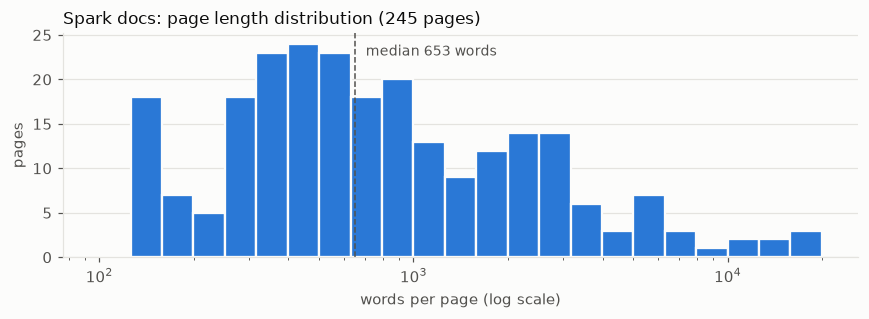

In [27]:
fig, ax = plt.subplots(figsize=(8, 3))
bins = [10 ** (x / 10) for x in range(20, 44)]
ax.hist(docs.words, bins=bins, color=CLASS_COLORS["bug"], edgecolor=SURFACE, linewidth=1.5)
ax.set_xscale("log")
ax.axvline(docs.words.median(), color=INK2, linewidth=1, linestyle="--")
ax.text(docs.words.median() * 1.08, ax.get_ylim()[1] * 0.9, f"median {int(docs.words.median()):,} words", color=INK2, fontsize=9)
ax.set_xlabel("words per page (log scale)")
ax.set_ylabel("pages")
ax.grid(axis="x", visible=False)
ax.set_title(f"Spark docs: page length distribution ({len(docs)} pages)", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_docs_length.png", bbox_inches="tight")
plt.show()

## 10. Extra evidence for the date-range decision: drift over time

Monthly volume per class and how Bug descriptions change by year.

Last month 2026-11 is partial (data downloaded mid-month): {'bug': np.int64(530), 'feature': np.int64(238), 'idea': np.int64(0), 'sub-task': np.int64(166), 'task': np.int64(5)}


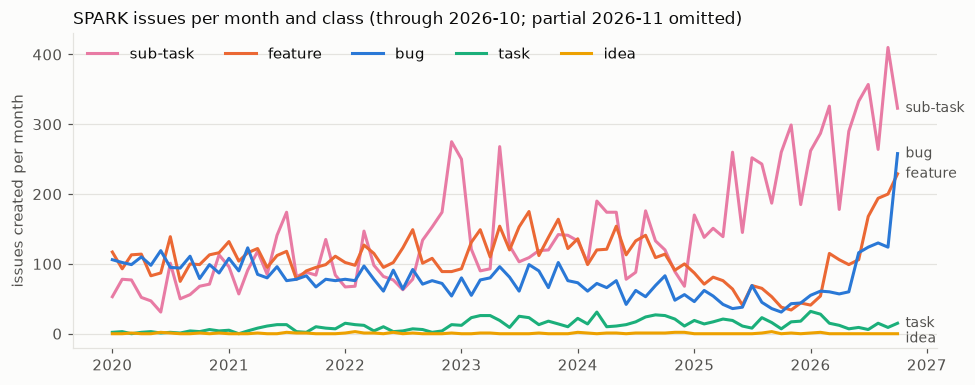

In [28]:
monthly = (spark.assign(group=spark.issuetype.map({"Sub-task": "sub-task"}).fillna(spark.class_core))
           .dropna(subset=["group"])
           .groupby([spark.created.dt.tz_localize(None).dt.to_period("M"), "group"]).size().unstack(fill_value=0))
partial = monthly.index[-1]
print(f"Last month {partial} is partial (data downloaded mid-month):", dict(monthly.loc[partial]))
full = monthly.iloc[:-1]

fig, ax = plt.subplots(figsize=(9, 3.6))
GROUPS = ["sub-task", "feature", "bug", "task", "idea"]
for g in GROUPS:
    ax.plot(full.index.to_timestamp(), full[g].values, color=CLASS_COLORS[g], linewidth=2, label=g)
# direct labels at the line ends, nudged apart so they don't collide
ends = sorted(((full[g].iat[-1], g) for g in GROUPS), reverse=True)
min_gap, prev = 22, None
for y, g in ends:
    y = y if prev is None else min(y, prev - min_gap)
    ax.text(full.index[-1].to_timestamp() + pd.Timedelta(days=25), y, g, color=INK2, fontsize=9, va="center")
    prev = y
ax.set_ylabel("issues created per month")
ax.legend(loc="upper left", ncols=5)
ax.set_title(f"SPARK issues per month and class (through {full.index[-1]}; partial {partial} omitted)", loc="left", fontsize=11)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_monthly_volume.png", bbox_inches="tight")
plt.show()

In [29]:
bug_years = spark[spark.issuetype == "Bug"].copy()
bug_years["jira_headings"] = bug_years.description.str.contains(r"(?m)^h[1-4]\. ")
bug_years["fix_section"] = bug_years.description.str.contains(r"(?i)root cause|(?:proposed|suggested) (?:fix|solution)")
bug_years["pr_label"] = bug_years.labels.map(lambda ls: "pull-request-available" in ls)
bug_years["connect"] = bug_years.components.map(lambda cs: "Connect" in cs)
drift = bug_years.groupby("year").agg(
    bugs=("key", "size"),
    desc_words_median=("desc_words", "median"),
    empty_pct=("empty_desc", lambda s: pct(s.mean())),
    jira_headings_pct=("jira_headings", lambda s: pct(s.mean())),
    root_cause_or_fix_pct=("fix_section", lambda s: pct(s.mean())),
    pr_label_pct=("pr_label", lambda s: pct(s.mean())),
    connect_component_pct=("connect", lambda s: pct(s.mean())),
    unresolved_pct=("resolution", lambda s: pct((s == "Unresolved").mean())),
)
show(drift)

| year | bugs | desc_words_median | empty_pct | jira_headings_pct | root_cause_or_fix_pct | pr_label_pct | connect_component_pct | unresolved_pct |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 2020 | 1199 | 88 | 6.3 | 1.2 | 1 | 0.8 | 0 | 17.7 |
| 2021 | 1040 | 77 | 7.1 | 0.8 | 1.3 | 1.2 | 0 | 23.6 |
| 2022 | 910 | 93 | 11 | 3.6 | 1.6 | 3 | 0.3 | 32.4 |
| 2023 | 963 | 63 | 18.5 | 2 | 2.2 | 32.5 | 10 | 29.1 |
| 2024 | 761 | 55 | 27.2 | 1.6 | 1.6 | 72.4 | 8.8 | 29 |
| 2025 | 546 | 50 | 25.1 | 2.6 | 3.3 | 77.7 | 13.4 | 31.5 |
| 2026 | 1575 | 114 | 17.3 | 11.6 | 11.4 | 89.2 | 29.8 | 30.1 |